# Bài 0 · Khởi động: NLP, môi trường và dữ liệu

**Thời lượng gợi ý:** 90 phút · **Cần:** Python cơ bản · **Không cần GPU**

## Mục tiêu

Sau bài này bạn có thể:

1. Kể tên các nhóm bài toán NLP và vẽ được một pipeline NLP điển hình.
2. Nêu ba điểm khiến tiếng Việt khác tiếng Anh khi xử lý máy: âm tiết ≠ từ, dấu thanh, Unicode.
3. Nạp, kiểm tra và mô tả một tập văn bản có nhãn; phát hiện trùng lặp và rò rỉ giữa train/test.
4. Dùng tập chia cố định và đặt **baseline** để mọi mô hình sau đó có mốc so sánh.

> **Nguyên tắc xuyên suốt cả khóa:** trước khi nói "mô hình tốt", hãy hỏi *so với cái gì* và *đo trên dữ liệu nào*.

## 1. NLP là gì, và gồm những bài toán nào?

*Xử lý ngôn ngữ tự nhiên* (Natural Language Processing, NLP) là việc dạy máy đọc, hiểu và sinh ngôn ngữ của con người. Phần lớn bài toán rơi vào vài nhóm:

| Nhóm | Đầu vào → đầu ra | Ví dụ tiếng Việt |
|---|---|---|
| Phân loại văn bản | văn bản → nhãn | cảm xúc của đánh giá, chủ đề tin, phát hiện spam |
| Gán nhãn chuỗi | chuỗi từ → nhãn cho từng từ | nhận diện tên người/địa danh (NER), gán nhãn từ loại |
| Quan hệ giữa văn bản | cặp văn bản → nhãn/điểm | hai câu có cùng nghĩa không, câu trả lời có đúng câu hỏi không |
| Truy hồi thông tin | truy vấn → danh sách văn bản | tìm đoạn FAQ phù hợp nhất |
| Sinh văn bản | văn bản → văn bản | dịch máy, tóm tắt, hỏi đáp, trợ lý hội thoại |

Một pipeline NLP điển hình:

```
văn bản thô → làm sạch/chuẩn hóa → tách câu, tách từ → biểu diễn số (vector)
            → mô hình → dự đoán → đánh giá & phân tích lỗi → triển khai & giám sát
```

Khóa học đi theo đúng thứ tự đó, từ biểu diễn thủ công (Bài 1–5) qua mạng nơ-ron (Bài 6–8) đến Transformer, PhoBERT, tìm kiếm ngữ nghĩa và LLM (Bài 9–14).

## 2. Chuẩn bị môi trường

Các ô dưới đây thêm thư mục gốc của dự án vào `sys.path` để import gói `nlpvi` (tiện ích dùng chung), rồi in phiên bản thư viện. **Hãy ghi lại các phiên bản này khi báo cáo kết quả** — cùng mã nguồn nhưng khác phiên bản có thể cho kết quả khác.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nlpvi import LABELS, load_reviews, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

In [2]:
import importlib, platform

print("Python", platform.python_version(), "·", platform.system())
for name in ["numpy", "pandas", "sklearn", "matplotlib", "torch", "transformers", "underthesea"]:
    try:
        m = importlib.import_module(name)
        print(f"  {name:13s} {getattr(m, '__version__', '?')}")
    except Exception as e:  # bắt rộng: gói thiếu HOẶC DLL bị chính sách hệ thống chặn
        print(f"  {name:13s} không dùng được ({type(e).__name__})")

Python 3.11.9 · Windows
  numpy         2.4.6
  pandas        2.3.3


  sklearn       1.7.2
  matplotlib    3.11.2
  torch         2.14.0+cu126


  transformers  5.17.0


  underthesea   9.5.0


> **Lưu ý khi một thư viện không import được.** Trên một số máy Windows, chính sách *Application Control* chặn tệp `.dll`/`.pyd` biên dịch sẵn (ví dụ của `underthesea_core`), cho ra `ImportError: DLL load failed`. Đó không phải lỗi cài đặt của bạn. Vì vậy khóa học này dùng bộ tách từ thuần Python làm mặc định, và chỉ dùng Underthesea khi nó chạy được. Xem thêm `docs/KHAC_PHUC_SU_CO.md`.

## 3. Ba điều cần nhớ về tiếng Việt

**(a) Âm tiết không phải là từ.** Tiếng Việt viết cách nhau bằng khoảng trắng *giữa các âm tiết*, không phải giữa các từ. "Học sinh" gồm hai âm tiết nhưng là một từ.

In [3]:
câu = "Học sinh đang học xử lý ngôn ngữ tự nhiên"
print("Số 'từ' nếu tách theo khoảng trắng :", len(câu.split()))
print("Số từ thật sự (đếm bằng tay)        : 6  → Học_sinh | đang | học | xử_lý | ngôn_ngữ | tự_nhiên")

Số 'từ' nếu tách theo khoảng trắng : 10
Số từ thật sự (đếm bằng tay)        : 6  → Học_sinh | đang | học | xử_lý | ngôn_ngữ | tự_nhiên


**(b) Dấu thanh và dấu phụ làm đổi nghĩa.** Sáu chữ dưới đây chỉ khác nhau ở dấu, nhưng là sáu từ khác nhau. Nếu bỏ dấu, máy không còn phân biệt được chúng (ta sẽ đo tác hại này ở Bài 1).

In [4]:
for w in ["ma", "má", "mà", "mả", "mã", "mạ"]:
    print(w, end="  ")
print("\n→ cùng 'ma' nếu bỏ dấu, nhưng nghĩa: ma / mẹ / liên từ 'nhưng' / mộ / mã / cây lúa non")

ma  má  mà  mả  mã  mạ  
→ cùng 'ma' nếu bỏ dấu, nhưng nghĩa: ma / mẹ / liên từ 'nhưng' / mộ / mã / cây lúa non


**(c) Cùng một chữ có thể có nhiều cách mã hóa Unicode.** Chữ "ệ" có thể là *một* ký tự dựng sẵn (NFC) hoặc *ba* ký tự: `e` + dấu mũ + dấu nặng (NFD). Hai chuỗi trông giống hệt nhau nhưng `==` trả về `False`.

In [5]:
import unicodedata

a = "học"                                  # dựng sẵn (NFC)
b = unicodedata.normalize("NFD", a)        # tổ hợp (NFD)
print(a, b, "| trông giống nhau")
print("len:", len(a), "vs", len(b), "| a == b ?", a == b)
print("sau khi chuẩn hóa NFC, a == b ?", unicodedata.normalize("NFC", b) == a)

học học | trông giống nhau
len: 3 vs 4 | a == b ? False
sau khi chuẩn hóa NFC, a == b ? True


→ Quy tắc đầu tiên của mọi pipeline tiếng Việt: **chuẩn hóa NFC ngay khi đọc dữ liệu**. Ta sẽ làm ở Bài 1.

## 4. Nạp và mô tả dữ liệu

Khóa học dùng bộ **`data/reviews_vi.csv`**: 1.800 đánh giá ngắn thuộc năm miền (sản phẩm, ứng dụng, ẩm thực, dịch vụ, khóa học) với ba nhãn: *tích cực*, *tiêu cực*, *trung tính*.

> ⚠️ Đây là dữ liệu **tổng hợp** từ mẫu câu có kiểm soát (xem `data/DATA_CARD.md`). Nó phù hợp để học quy trình và để mọi kết quả chạy lại được, nhưng **không** đại diện cho bình luận thật. Ở các bài sau, những ô có đánh dấu *“dữ liệu thật”* sẽ dùng bộ UIT-VSFC và PhoNER.

In [6]:
df = load_reviews()
print(df.shape)
df.head(8)

(1800, 5)


,id,text,label,domain,split
0,r0001,tư vấn của shop chậm. sẽ không quay lại!!!,tiêu cực,sản phẩm,train
1,r0002,"Tài liệu rất thiếu, nhưng nội dung có hệ thống.",tích cực,khóa học,valid
2,r0003,Thực đơn khá nhiều món!!!,trung tính,ẩm thực,train
3,r0004,"Tính năng rất đầy đủ, lại còn ứng dụng rất ổn ...",tích cực,ứng dụng,train
4,r0005,Chạy bình thường trên máy mình. Thông báo khó ...,tiêu cực,ứng dụng,test
5,r0006,tuy giá chát nhưng không gian sạch sẽ. cho 5 sao.,tích cực,ẩm thực,train
6,r0007,Mình dùng dịch vụ lần thứ hai. Phòng ốc không ...,tích cực,dịch vụ,valid
7,r0008,Mình mới cài nên chưa dùng nhiều. 🤔,trung tính,ứng dụng,train


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      1800 non-null   object
 1   text    1800 non-null   object
 2   label   1800 non-null   object
 3   domain  1800 non-null   object
 4   split   1800 non-null   object
dtypes: object(5)
memory usage: 70.4+ KB


### 4.1 Phân phối nhãn và miền

Lớp không cân bằng là chuyện bình thường. Nó quyết định ta nên dùng độ đo nào (Bài 3).

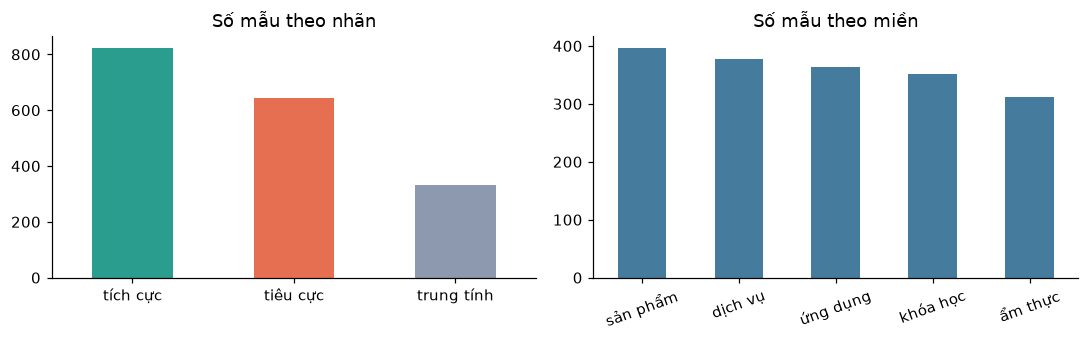

label
tích cực      0.458
tiêu cực      0.358
trung tính    0.184


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
df["label"].value_counts().reindex(LABELS).plot.bar(ax=axes[0], color=["#2a9d8f", "#e76f51", "#8d99ae"], rot=0)
axes[0].set_title("Số mẫu theo nhãn"); axes[0].set_xlabel("")
df["domain"].value_counts().plot.bar(ax=axes[1], color="#457b9d", rot=20)
axes[1].set_title("Số mẫu theo miền"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(df["label"].value_counts(normalize=True).round(3).to_string())

In [9]:
pd.crosstab(df["domain"], df["label"], margins=True)

label,tiêu cực,trung tính,tích cực,All
domain,,,,
dịch vụ,141,68,168,377
khóa học,135,71,146,352
sản phẩm,131,68,198,397
ẩm thực,117,56,138,311
ứng dụng,121,68,174,363
All,645,331,824,1800


### 4.2 Độ dài văn bản

Độ dài quyết định cách ta cắt/đệm chuỗi khi huấn luyện mạng nơ-ron và giới hạn token của mô hình (PhoBERT chỉ nhận tối đa 256 token).

       so_am_tiet  so_ky_tu
count      1800.0    1800.0
mean         11.4      51.9
std           5.0      23.3
min           2.0       7.0
25%           8.0      34.0
50%          11.0      51.0
75%          15.0      67.0
max          32.0     149.0


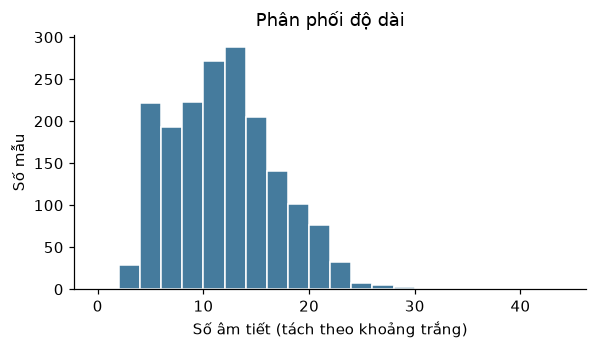

In [10]:
df["so_am_tiet"] = df["text"].str.split().str.len()
df["so_ky_tu"] = df["text"].str.len()

print(df[["so_am_tiet", "so_ky_tu"]].describe().round(1).to_string())

plt.figure(figsize=(6, 3))
df["so_am_tiet"].plot.hist(bins=range(0, 45, 2), color="#457b9d", edgecolor="white")
plt.xlabel("Số âm tiết (tách theo khoảng trắng)"); plt.ylabel("Số mẫu"); plt.title("Phân phối độ dài")
plt.show()

### 4.3 Kiểm tra chất lượng: thiếu, trùng, ký tự lạ

Làm sạch dữ liệu thường tốn nhiều thời gian hơn huấn luyện mô hình. Ba câu hỏi nên hỏi trước tiên:

1. Có dòng trống hoặc nhãn thiếu không?
2. Có văn bản trùng lặp (kể cả "gần như trùng") không?
3. Có ký tự bất thường (emoji, ký tự điều khiển, mã hóa hỏng) không?

In [11]:
print("Dòng thiếu text :", df["text"].isna().sum())
print("Dòng thiếu nhãn :", df["label"].isna().sum())
print("Trùng đúng từng ký tự :", df["text"].duplicated().sum())

# Ký tự '?' dày đặc là dấu hiệu tệp đã bị ghi sai mã hóa (mất dấu tiếng Việt vĩnh viễn)
print("Số ký tự '?' trong toàn bộ văn bản:", df["text"].str.count(r"\?").sum())

# Tỉ lệ dòng có ký tự ngoài tiếng Việt thông thường (đa phần là emoji)
non_vi = df["text"].str.contains(r"[^\w\s.,!?:;\-\"'()%/…]", regex=True)
print(f"Dòng có ký tự đặc biệt/emoji: {non_vi.mean():.1%}")
df.loc[non_vi, "text"].head(5).tolist()

Dòng thiếu text : 0
Dòng thiếu nhãn : 0
Trùng đúng từng ký tự : 0
Số ký tự '?' trong toàn bộ văn bản: 0
Dòng có ký tự đặc biệt/emoji: 14.9%


['Chạy bình thường trên máy mình. Thông báo khó hiểu. 😞',
 'Mình mới cài nên chưa dùng nhiều. 🤔',
 'Di cong tac nen minh ghe. Chi phi ko minh bach chut nao. Phong oc chat. Se khong quay lai. 😐',
 'Cài về từ tháng trước. Tính năng khá đầy đủ. Recommend nhé! 👍',
 'Giao hàng quá nhanh, lại còn đóng gói rất cẩn thận. Rất đáng thử. 😍...']

## 5. Chia tập và rò rỉ dữ liệu

Dữ liệu được chia sẵn bằng cột `split`: 70% *train*, 15% *valid*, 15% *test*. Cách chia là **tất định**: băm `id` bằng MD5 rồi lấy phần dư mod 100 (xem `tools/make_data.py`). Nhờ vậy:

- chạy lại ở máy khác vẫn ra đúng tập cũ;
- thêm dữ liệu mới không làm đảo các mẫu đã có sang tập khác.

| Tập | Dùng để | Quy tắc |
|---|---|---|
| train | học tham số (và "học" từ điển/TF-IDF) | được xem thoải mái |
| valid | chọn mô hình, chỉnh siêu tham số | xem nhiều lần |
| test | báo cáo kết quả cuối cùng | **chỉ xem một lần ở cuối** |

In [12]:
print(pd.crosstab(df["split"], df["label"], normalize="index").round(3).to_string())
print()
print(df["split"].value_counts().to_string())

label  tiêu cực  trung tính  tích cực
split                                
test      0.342       0.149     0.509
train     0.364       0.189     0.448
valid     0.349       0.197     0.454

split
train    1262
valid     269
test      269


### 5.1 Rò rỉ qua câu gần như trùng

Hai câu "Giao hàng rất nhanh!" và "giao hang rat nhanh" không trùng từng ký tự nhưng gần như giống hệt. Nếu một câu nằm ở train còn câu kia nằm ở test, mô hình chỉ cần *nhớ* là đã "làm đúng" bài thi. Ta chuẩn hóa mạnh (bỏ dấu, hạ chữ, bỏ dấu câu/emoji) để tìm trùng lặp ẩn.

In [13]:
import re
from nlpvi import normalize, strip_accents

def khoa_trung(text):
    t = strip_accents(normalize(text, expand_teencode=False, emoji="drop"))
    return re.sub(r"[^a-z0-9 ]", "", t.lower()).strip()

df["khoa"] = df["text"].map(khoa_trung)
print("Số mẫu:", len(df), "| số khóa duy nhất:", df["khoa"].nunique())

tap = {s: set(df.loc[df["split"] == s, "khoa"]) for s in ["train", "valid", "test"]}
for s in ["valid", "test"]:
    ti_le = df[df["split"] == s]["khoa"].isin(tap["train"]).mean()
    print(f"Tỉ lệ mẫu '{s}' có bản trùng ẩn trong train: {ti_le:.1%}")

Số mẫu: 1800 | số khóa duy nhất: 1742
Tỉ lệ mẫu 'valid' có bản trùng ẩn trong train: 4.8%
Tỉ lệ mẫu 'test' có bản trùng ẩn trong train: 5.2%


**Đọc kết quả.** Khoảng 5% mẫu ở valid/test có một bản sao ẩn trong train. Con số này không lớn nhưng cũng không bằng 0, và nó chỉ là phần *nhìn thấy được*: vì dữ liệu tổng hợp ghép từ một số ít **mẫu câu**, tập train và test còn chia sẻ cùng khuôn câu dù không trùng khít. Hệ quả: điểm trên `valid`/`test` sẽ **cao hơn** điểm bạn nhận được trên bình luận ngoài đời. Đó là lý do khóa học có thêm `data/reviews_hard.csv` (40 câu viết tay, cố ý khó) để thử sức mô hình ở Bài 3.

Với dự án thật: gom các mẫu trùng ẩn vào **cùng một tập** (hoặc loại bỏ) *trước khi* chia; nếu dữ liệu có nhiều bình luận của cùng một người, chia theo người (group split).

## 6. Baseline: mốc phải vượt qua

Mô hình ngốc nhất — luôn đoán nhãn phổ biến nhất — cho ta một con số mốc. Mọi mô hình phức tạp hơn phải thắng được nó *một cách có ý nghĩa*.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

train = df[df["split"] == "train"]
valid = df[df["split"] == "valid"]

dummy = DummyClassifier(strategy="most_frequent").fit(train[["text"]], train["label"])
pred = dummy.predict(valid[["text"]])
print("Nhãn luôn đoán:", pred[0])
print(f"Accuracy : {accuracy_score(valid['label'], pred):.3f}")
print(f"Macro-F1 : {f1_score(valid['label'], pred, average='macro'):.3f}")

Nhãn luôn đoán: tích cực
Accuracy : 0.454
Macro-F1 : 0.208


Accuracy của mô hình ngốc đã khoảng 0,45 vì nhãn *tích cực* chiếm gần một nửa dữ liệu, trong khi **macro-F1 chỉ khoảng 0,2** vì mô hình không bao giờ nhận ra hai lớp còn lại. Vì lớp không cân bằng, ta sẽ ưu tiên **macro-F1** (trung bình F1 của từng lớp) thay vì chỉ nhìn accuracy.

## 7. Tổng kết

- NLP có vài nhóm bài toán chính; pipeline đi từ văn bản thô → vector → mô hình → đánh giá.
- Tiếng Việt: âm tiết ≠ từ; dấu thanh đổi nghĩa; luôn chuẩn hóa Unicode NFC.
- Luôn kiểm tra: thiếu, trùng (kể cả trùng ẩn), mã hóa hỏng, phân phối nhãn.
- Chia train/valid/test một lần, cố định, và chỉ mở test ở cuối.
- Luôn có baseline; với lớp lệch, báo cáo macro-F1.

## Bài tập

1. **(Dễ)** Tính độ dài trung bình (số âm tiết) theo từng nhãn. Nhãn nào dài nhất? Giả thuyết của bạn vì sao?
2. **(Dễ)** Vẽ biểu đồ cột chồng thể hiện tỉ lệ ba nhãn trong từng miền. Miền nào lệch nhãn nhiều nhất?
3. **(Vừa)** Mở rộng hàm `khoa_trung` để cũng gộp teencode (`ko`→`không`, `dc`→`được`). Tỉ lệ trùng ẩn tăng bao nhiêu?
4. **(Vừa)** Chia ngẫu nhiên lại bằng `train_test_split(..., random_state=0)` rồi so sánh tỉ lệ nhãn với cột `split`. Vì sao nên dùng `stratify=`?
5. **(Khó)** Viết hàm kiểm tra *group leakage*: giả sử mỗi `id` thuộc một "người dùng" (lấy `int(id[1:]) % 200`). Có người nào xuất hiện ở cả train và test không? Đề xuất cách chia theo nhóm với `GroupShuffleSplit`.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `df.groupby("label")["so_am_tiet"].mean()`. Nhãn *trung tính* thường dài hơn vì hay kèm câu mô tả bối cảnh; *tiêu cực* thường kèm lý do.
2. `pd.crosstab(df.domain, df.label, normalize="index").plot.bar(stacked=True)`.
3. Chạy `normalize(text, expand_teencode=True)` trước khi bỏ dấu. Thông thường tỉ lệ trùng ẩn tăng nhẹ.
4. `stratify=df["label"]` giữ tỉ lệ nhãn như nhau ở mọi tập, quan trọng khi một lớp hiếm (ở đây *trung tính* ~18%).
5. `GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0).split(df, groups=nhom)`; kiểm tra `set(nhom[train]) & set(nhom[test])` rỗng.
</details>

**Tiếp theo → Bài 1:** làm sạch và tách từ tiếng Việt.

**Đọc thêm:** [Hugging Face NLP Course, Chương 1 (bản tiếng Việt)](https://huggingface.co/docs/course/vi/chapter1/1) — giới thiệu Transformer và các tác vụ NLP.